In [1]:

import os

print(os.listdir("/content"))


['.config', 'training_set_features.csv', 'test_set_features.csv', 'training_set_labels.csv', 'sample_data']


In [2]:

import pandas as pd

# Load the three CSV files
features = pd.read_csv("/content/training_set_features.csv")
labels = pd.read_csv("/content/training_set_labels.csv")
test_features = pd.read_csv("/content/test_set_features.csv")

print("Training features:", features.shape)
print("Training labels:", labels.shape)
print("Test features:", test_features.shape)


Training features: (26707, 36)
Training labels: (26707, 3)
Test features: (26708, 36)


In [3]:

# Display the first five rows of the training data
features.head()


,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,income_poverty,marital_status,rent_or_own,employment_status,hhs_geo_region,census_msa,household_adults,household_children,employment_industry,employment_occupation
0,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,...,Below Poverty,Not Married,Own,Not in Labor Force,oxchjgsf,Non-MSA,0.0,0.0,NaN,NaN
1,1,3.0,2.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,Below Poverty,Not Married,Rent,Employed,bhuqouqj,"MSA, Not Principle City",0.0,0.0,pxcmvdjn,xgwztkwe
2,2,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,"<= $75,000, Above Poverty",Not Married,Own,Employed,qufhixun,"MSA, Not Principle City",2.0,0.0,rucpziij,xtkaffoo
3,3,1.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,...,Below Poverty,Not Married,Rent,Not in Labor Force,lrircsnp,"MSA, Principle City",0.0,0.0,NaN,NaN
4,4,2.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,...,"<= $75,000, Above Poverty",Married,Own,Employed,qufhixun,"MSA, Not Principle City",1.0,0.0,wxleyezf,emcorrxb


In [4]:

labels.head()


,respondent_id,h1n1_vaccine,seasonal_vaccine
0,0,0,0
1,1,0,1
2,2,0,0
3,3,0,1
4,4,0,0


In [5]:

print("H1N1 vaccination outcomes:")
print(labels["h1n1_vaccine"].value_counts())

print("\nSeasonal vaccination outcomes:")
print(labels["seasonal_vaccine"].value_counts())


H1N1 vaccination outcomes:
h1n1_vaccine
0    21033
1     5674
Name: count, dtype: int64

Seasonal vaccination outcomes:
seasonal_vaccine
0    14272
1    12435
Name: count, dtype: int64


In [6]:

print("Training data information:")
features.info()

print("\nMissing values in the training data:")
print(features.isnull().sum().sort_values(ascending=False).head(10))


Training data information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26707 entries, 0 to 26706
Data columns (total 36 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   respondent_id                26707 non-null  int64  
 1   h1n1_concern                 26615 non-null  float64
 2   h1n1_knowledge               26591 non-null  float64
 3   behavioral_antiviral_meds    26636 non-null  float64
 4   behavioral_avoidance         26499 non-null  float64
 5   behavioral_face_mask         26688 non-null  float64
 6   behavioral_wash_hands        26665 non-null  float64
 7   behavioral_large_gatherings  26620 non-null  float64
 8   behavioral_outside_home      26625 non-null  float64
 9   behavioral_touch_face        26579 non-null  float64
 10  doctor_recc_h1n1             24547 non-null  float64
 11  doctor_recc_seasonal         24547 non-null  float64
 12  chronic_med_condition        25736 non-null  fl

In [7]:

# Count the outcomes for each vaccine

print("H1N1 vaccine:")
print(labels["h1n1_vaccine"].value_counts())
print(labels["h1n1_vaccine"].value_counts(normalize=True) * 100)

print("\nSeasonal flu vaccine:")
print(labels["seasonal_vaccine"].value_counts())
print(labels["seasonal_vaccine"].value_counts(normalize=True) * 100)


H1N1 vaccine:
h1n1_vaccine
0    21033
1     5674
Name: count, dtype: int64
h1n1_vaccine
0    78.754634
1    21.245366
Name: proportion, dtype: float64

Seasonal flu vaccine:
seasonal_vaccine
0    14272
1    12435
Name: count, dtype: int64
seasonal_vaccine
0    53.439173
1    46.560827
Name: proportion, dtype: float64


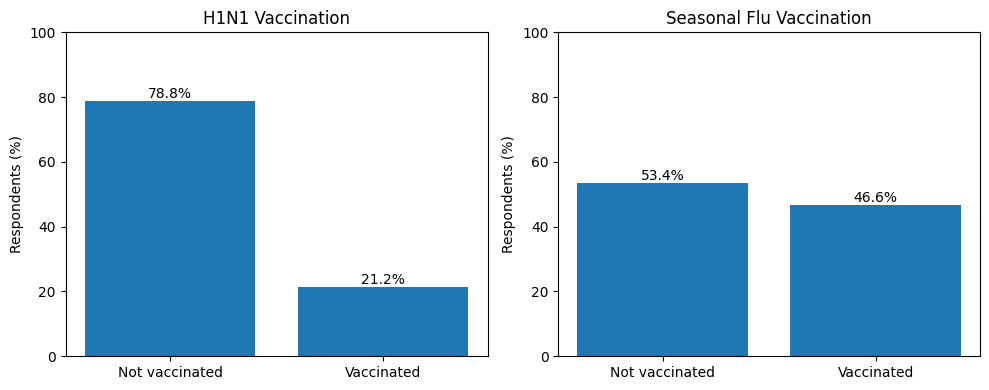

In [8]:

import matplotlib.pyplot as plt

# Calculate vaccination percentages
h1n1_rates = labels["h1n1_vaccine"].value_counts(normalize=True).sort_index() * 100
seasonal_rates = labels["seasonal_vaccine"].value_counts(normalize=True).sort_index() * 100

# Create two side-by-side charts
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].bar(["Not vaccinated", "Vaccinated"], h1n1_rates.values)
axes[0].set_title("H1N1 Vaccination")
axes[0].set_ylabel("Respondents (%)")
axes[0].set_ylim(0, 100)

axes[1].bar(["Not vaccinated", "Vaccinated"], seasonal_rates.values)
axes[1].set_title("Seasonal Flu Vaccination")
axes[1].set_ylabel("Respondents (%)")
axes[1].set_ylim(0, 100)

# Add percentage labels above each bar
for ax in axes:
    for bar in ax.patches:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1,
            f"{bar.get_height():.1f}%",
            ha="center"
        )

plt.tight_layout()
plt.show()


In [9]:

# Compare the two vaccination outcomes

vaccine_comparison = pd.crosstab(
    labels["h1n1_vaccine"],
    labels["seasonal_vaccine"],
    margins=True
)

vaccine_comparison


seasonal_vaccine,0,1,All
h1n1_vaccine,,,
0,13295,7738,21033
1,977,4697,5674
All,14272,12435,26707


In [10]:

# Among H1N1 vaccination groups, compare seasonal vaccination rates

seasonal_by_h1n1 = pd.crosstab(
    labels["h1n1_vaccine"],
    labels["seasonal_vaccine"],
    normalize="index"
) * 100

seasonal_by_h1n1.index = ["H1N1 not vaccinated", "H1N1 vaccinated"]
seasonal_by_h1n1.columns = [
    "Seasonal not vaccinated",
    "Seasonal vaccinated"
]

seasonal_by_h1n1.round(2)


,Seasonal not vaccinated,Seasonal vaccinated
H1N1 not vaccinated,63.21,36.79
H1N1 vaccinated,17.22,82.78


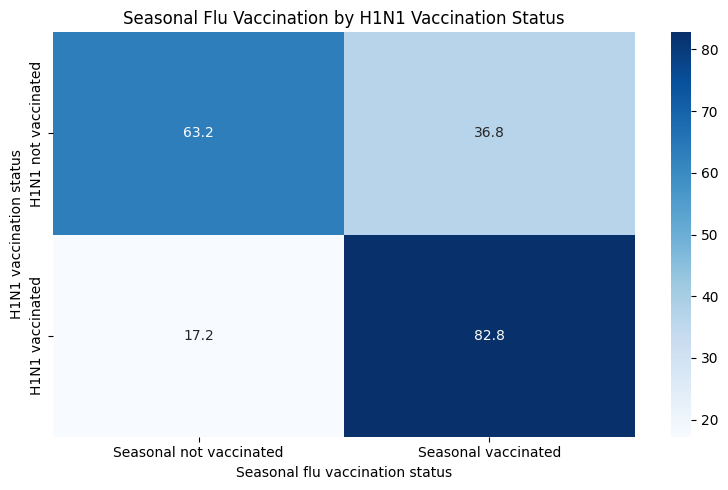

In [11]:

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

sns.heatmap(
    seasonal_by_h1n1,
    annot=True,
    fmt=".1f",
    cmap="Blues"
)

plt.title("Seasonal Flu Vaccination by H1N1 Vaccination Status")
plt.ylabel("H1N1 vaccination status")
plt.xlabel("Seasonal flu vaccination status")
plt.tight_layout()
plt.show()


In [12]:

# Look at the two doctor recommendation columns
print(features[
    ["doctor_recc_h1n1", "doctor_recc_seasonal"]
].head(10))


   doctor_recc_h1n1  doctor_recc_seasonal
0               0.0                   0.0
1               0.0                   0.0
2               NaN                   NaN
3               0.0                   1.0
4               0.0                   0.0
5               0.0                   1.0
6               0.0                   0.0
7               1.0                   0.0
8               0.0                   0.0
9               0.0                   0.0


In [13]:

# Combine the training features and vaccination outcomes
data = features.merge(
    labels,
    on="respondent_id",
    how="inner"
)

print("Combined dataset shape:", data.shape)

data[[
    "doctor_recc_h1n1",
    "doctor_recc_seasonal",
    "h1n1_vaccine",
    "seasonal_vaccine"
]].head()


Combined dataset shape: (26707, 38)


,doctor_recc_h1n1,doctor_recc_seasonal,h1n1_vaccine,seasonal_vaccine
0,0.0,0.0,0,0
1,0.0,0.0,0,1
2,NaN,NaN,0,0
3,0.0,1.0,0,1
4,0.0,0.0,0,0


In [14]:

# H1N1 vaccination rate by doctor recommendation
h1n1_recommendation_rates = data.groupby(
    "doctor_recc_h1n1"
)["h1n1_vaccine"].mean() * 100

print("H1N1 vaccination rate by doctor recommendation:")
print(h1n1_recommendation_rates)

# Seasonal vaccination rate by doctor recommendation
seasonal_recommendation_rates = data.groupby(
    "doctor_recc_seasonal"
)["seasonal_vaccine"].mean() * 100

print("\nSeasonal vaccination rate by doctor recommendation:")
print(seasonal_recommendation_rates)


H1N1 vaccination rate by doctor recommendation:
doctor_recc_h1n1
0.0    13.637076
1.0    53.235947
Name: h1n1_vaccine, dtype: float64

Seasonal vaccination rate by doctor recommendation:
doctor_recc_seasonal
0.0    34.625904
1.0    73.844823
Name: seasonal_vaccine, dtype: float64


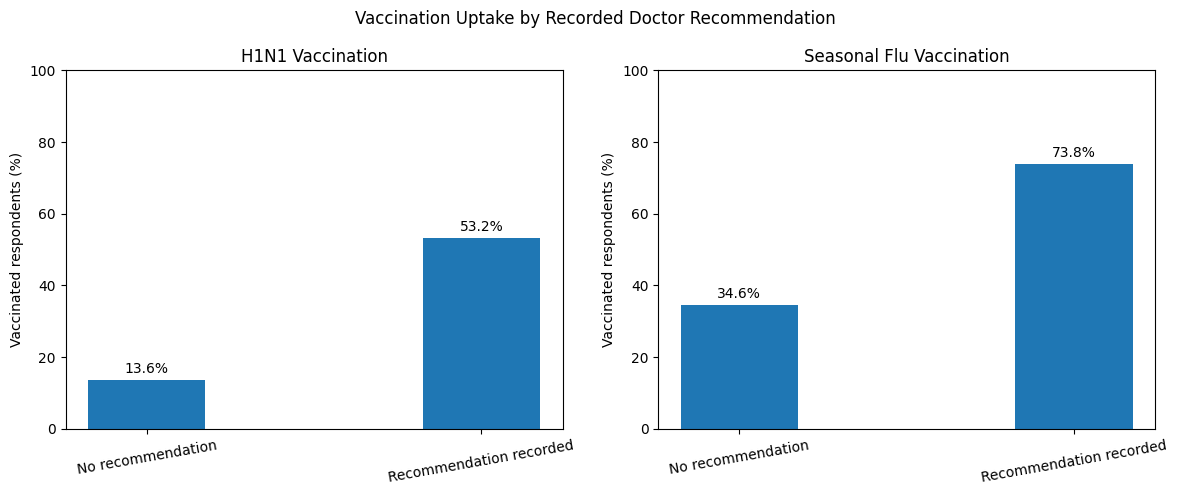

In [15]:

import matplotlib.pyplot as plt
import numpy as np

categories = ["No recommendation", "Recommendation recorded"]

h1n1_values = h1n1_recommendation_rates.loc[[0.0, 1.0]].values
seasonal_values = seasonal_recommendation_rates.loc[[0.0, 1.0]].values

x = np.arange(len(categories))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(x, h1n1_values, width)
axes[0].set_title("H1N1 Vaccination")
axes[0].set_ylabel("Vaccinated respondents (%)")
axes[0].set_xticks(x, categories, rotation=10)
axes[0].set_ylim(0, 100)

axes[1].bar(x, seasonal_values, width)
axes[1].set_title("Seasonal Flu Vaccination")
axes[1].set_ylabel("Vaccinated respondents (%)")
axes[1].set_xticks(x, categories, rotation=10)
axes[1].set_ylim(0, 100)

for ax in axes:
    for bar in ax.patches:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 2,
            f"{bar.get_height():.1f}%",
            ha="center"
        )

plt.suptitle("Vaccination Uptake by Recorded Doctor Recommendation")
plt.tight_layout()
plt.show()


In [16]:

opinion_columns = [
    "opinion_h1n1_vacc_effective",
    "opinion_h1n1_risk",
    "opinion_h1n1_sick_from_vacc",
    "opinion_seas_vacc_effective",
    "opinion_seas_risk",
    "opinion_seas_sick_from_vacc"
]

print(data[opinion_columns].describe().round(2))


       opinion_h1n1_vacc_effective  opinion_h1n1_risk  \
count                     26316.00           26319.00   
mean                          3.85               2.34   
std                           1.01               1.29   
min                           1.00               1.00   
25%                           3.00               1.00   
50%                           4.00               2.00   
75%                           5.00               4.00   
max                           5.00               5.00   

       opinion_h1n1_sick_from_vacc  opinion_seas_vacc_effective  \
count                     26312.00                     26245.00   
mean                          2.36                         4.03   
std                           1.36                         1.09   
min                           1.00                         1.00   
25%                           1.00                         4.00   
50%                           2.00                         4.00   
75%              

In [17]:

# Compare vaccination rates across H1N1 opinion scores

for column in opinion_columns[:3]:
    print(f"\nVaccination rates by {column}:")

    result = data.groupby(column, observed=True)[
        "h1n1_vaccine"
    ].agg(["mean", "count"])

    result["mean"] = result["mean"] * 100
    result = result.rename(
        columns={
            "mean": "vaccinated_percent",
            "count": "respondents"
        }
    )

    print(result.round(2))



Vaccination rates by opinion_h1n1_vacc_effective:
                             vaccinated_percent  respondents
opinion_h1n1_vacc_effective                                 
1.0                                        4.74          886
2.0                                        5.11         1858
3.0                                       10.57         4723
4.0                                       17.64        11683
5.0                                       40.48         7166

Vaccination rates by opinion_h1n1_risk:
                   vaccinated_percent  respondents
opinion_h1n1_risk                                 
1.0                              8.83         8139
2.0                             16.80         9919
3.0                             17.37         1117
4.0                             39.21         5394
5.0                             51.09         1750

Vaccination rates by opinion_h1n1_sick_from_vacc:
                             vaccinated_percent  respondents
opinion_h1n1

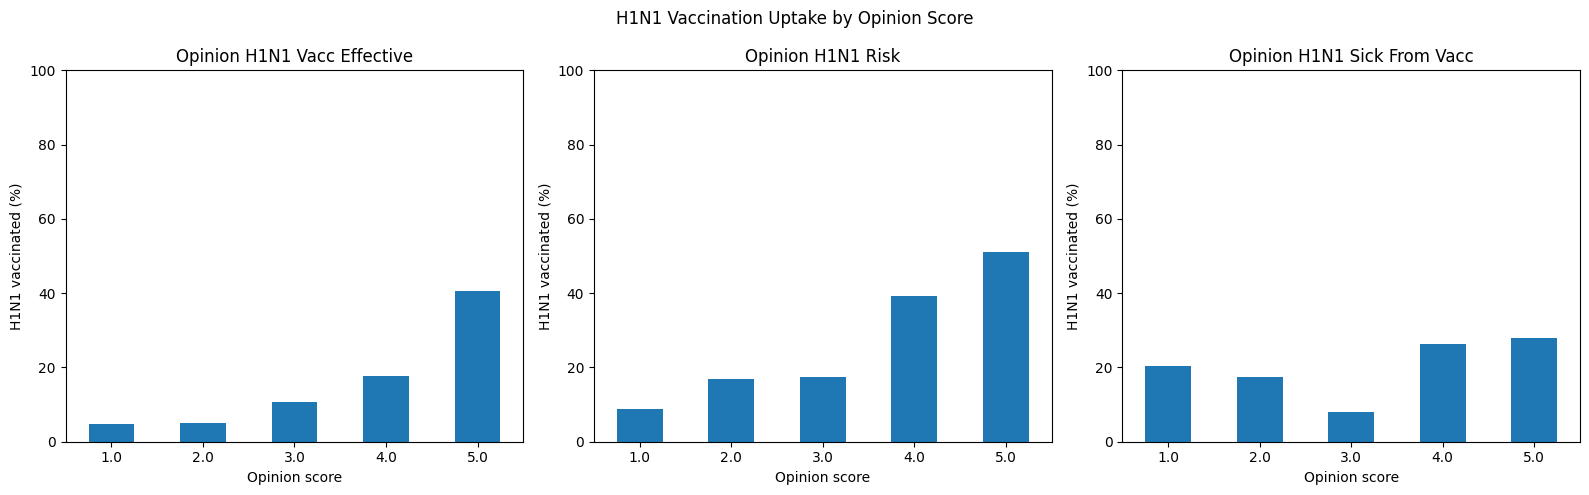

In [18]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, column in zip(axes, opinion_columns[:3]):
    rates = data.groupby(column, observed=True)[
        "h1n1_vaccine"
    ].mean() * 100

    rates.plot(kind="bar", ax=ax)
    ax.set_title(column.replace("_", " ").title())
    ax.set_xlabel("Opinion score")
    ax.set_ylabel("H1N1 vaccinated (%)")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=0)

plt.suptitle("H1N1 Vaccination Uptake by Opinion Score")
plt.tight_layout()
plt.show()


In [19]:

print(data["age_group"].value_counts())

print("\nH1N1 vaccination rate by age group:")

age_vaccination = data.groupby("age_group")[
    "h1n1_vaccine"
].agg(["mean", "count"])

age_vaccination["mean"] *= 100

age_vaccination = age_vaccination.rename(
    columns={
        "mean": "vaccinated_percent",
        "count": "respondents"
    }
)

print(age_vaccination.round(2))


age_group
65+ Years        6843
55 - 64 Years    5563
45 - 54 Years    5238
18 - 34 Years    5215
35 - 44 Years    3848
Name: count, dtype: int64

H1N1 vaccination rate by age group:
               vaccinated_percent  respondents
age_group                                     
18 - 34 Years               19.00         5215
35 - 44 Years               19.78         3848
45 - 54 Years               19.47         5238
55 - 64 Years               24.29         5563
65+ Years                   22.67         6843


In [20]:

print(data["age_group"].value_counts())

print("\nH1N1 vaccination rate by age group:")

age_vaccination = data.groupby("age_group")[
    "h1n1_vaccine"
].agg(["mean", "count"])

age_vaccination["mean"] *= 100

age_vaccination = age_vaccination.rename(
    columns={
        "mean": "vaccinated_percent",
        "count": "respondents"
    }
)

print(age_vaccination.round(2))


age_group
65+ Years        6843
55 - 64 Years    5563
45 - 54 Years    5238
18 - 34 Years    5215
35 - 44 Years    3848
Name: count, dtype: int64

H1N1 vaccination rate by age group:
               vaccinated_percent  respondents
age_group                                     
18 - 34 Years               19.00         5215
35 - 44 Years               19.78         3848
45 - 54 Years               19.47         5238
55 - 64 Years               24.29         5563
65+ Years                   22.67         6843


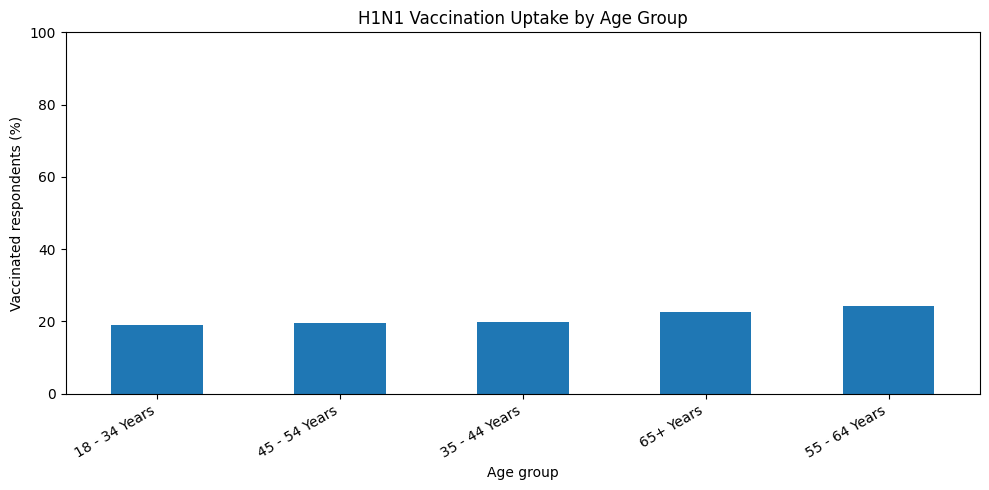

In [21]:

import matplotlib.pyplot as plt

age_rates = (
    data.groupby("age_group")["h1n1_vaccine"].mean() * 100
).sort_values()

plt.figure(figsize=(10, 5))
age_rates.plot(kind="bar")

plt.title("H1N1 Vaccination Uptake by Age Group")
plt.xlabel("Age group")
plt.ylabel("Vaccinated respondents (%)")
plt.ylim(0, 100)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


Seasonal vaccination rate by age group:
age_group
18 - 34 Years    28.46
35 - 44 Years    36.25
45 - 54 Years    40.13
55 - 64 Years    51.12
65+ Years        67.37
Name: seasonal_vaccine, dtype: float64


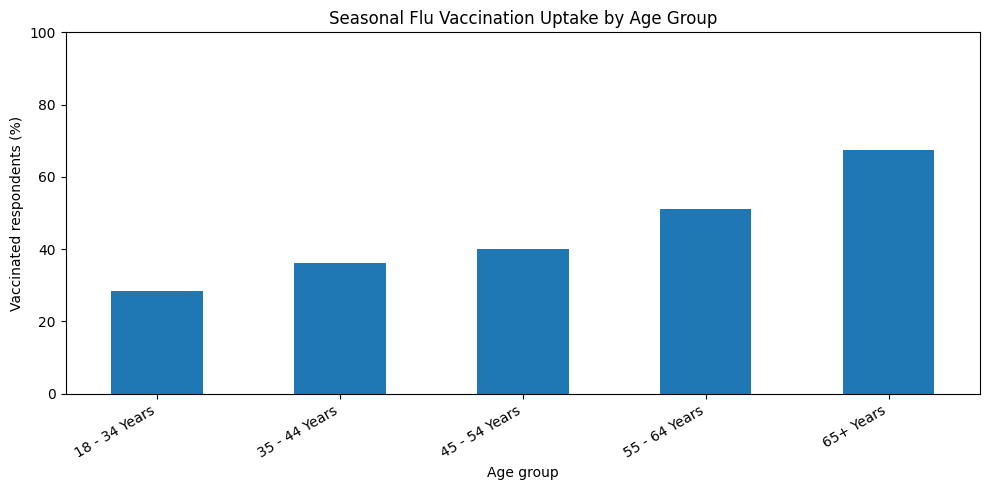

In [22]:

# Calculate seasonal vaccination rates by age group

seasonal_age_rates = (
    data.groupby("age_group")["seasonal_vaccine"].mean() * 100
).sort_values()

print("Seasonal vaccination rate by age group:")
print(seasonal_age_rates.round(2))

# Visualise the rates
plt.figure(figsize=(10, 5))
seasonal_age_rates.plot(kind="bar")

plt.title("Seasonal Flu Vaccination Uptake by Age Group")
plt.xlabel("Age group")
plt.ylabel("Vaccinated respondents (%)")
plt.ylim(0, 100)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


In [23]:

# Step 1: Check missing values in the training features

missing_values = features.isnull().sum()

missing_values = missing_values[missing_values > 0].sort_values(
    ascending=False
)

print("Columns containing missing values:")
print(missing_values)

print("\nTotal missing cells:", features.isnull().sum().sum())

print("\nDuplicate rows in training features:", features.duplicated().sum())


Columns containing missing values:
employment_occupation          13470
employment_industry            13330
health_insurance               12274
income_poverty                  4423
doctor_recc_seasonal            2160
doctor_recc_h1n1                2160
rent_or_own                     2042
employment_status               1463
marital_status                  1408
education                       1407
chronic_med_condition            971
child_under_6_months             820
health_worker                    804
opinion_seas_sick_from_vacc      537
opinion_seas_risk                514
opinion_seas_vacc_effective      462
opinion_h1n1_sick_from_vacc      395
opinion_h1n1_vacc_effective      391
opinion_h1n1_risk                388
household_children               249
household_adults                 249
behavioral_avoidance             208
behavioral_touch_face            128
h1n1_knowledge                   116
h1n1_concern                      92
behavioral_large_gatherings       87
beh

In [24]:

# Step 2: Identify numerical and categorical columns

numerical_columns = features.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_columns = features.select_dtypes(
    include=["object"]
).columns.tolist()

print("Number of numerical columns:", len(numerical_columns))
print("Number of categorical columns:", len(categorical_columns))

print("\nNumerical columns:")
print(numerical_columns)

print("\nCategorical columns:")
print(categorical_columns)


Number of numerical columns: 24
Number of categorical columns: 12

Numerical columns:
['respondent_id', 'h1n1_concern', 'h1n1_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'doctor_recc_h1n1', 'doctor_recc_seasonal', 'chronic_med_condition', 'child_under_6_months', 'health_worker', 'health_insurance', 'opinion_h1n1_vacc_effective', 'opinion_h1n1_risk', 'opinion_h1n1_sick_from_vacc', 'opinion_seas_vacc_effective', 'opinion_seas_risk', 'opinion_seas_sick_from_vacc', 'household_adults', 'household_children']

Categorical columns:
['age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status', 'rent_or_own', 'employment_status', 'hhs_geo_region', 'census_msa', 'employment_industry', 'employment_occupation']


In [25]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# The ID is not a useful predictive feature
X = features.drop(columns=["respondent_id"])

# The two outcomes we want to predict
y = labels[["h1n1_vaccine", "seasonal_vaccine"]]

# Treat health_insurance as categorical
numerical_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_columns = X.select_dtypes(
    include=["object"]
).columns.tolist()

if "health_insurance" in numerical_columns:
    numerical_columns.remove("health_insurance")
    categorical_columns.append("health_insurance")

# Numerical preprocessing
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_pipeline, numerical_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

print("Preprocessing pipeline created successfully!")
print("Numerical features:", len(numerical_columns))
print("Categorical features:", len(categorical_columns))
print("Target columns:", list(y.columns))



Preprocessing pipeline created successfully!
Numerical features: 22
Categorical features: 13
Target columns: ['h1n1_vaccine', 'seasonal_vaccine']


In [26]:

from sklearn.model_selection import train_test_split

# Split the features and both target variables
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y["h1n1_vaccine"]
)

print("Training features:", X_train.shape)
print("Validation features:", X_valid.shape)

print("\nTraining targets:", y_train.shape)
print("Validation targets:", y_valid.shape)

print("\nH1N1 vaccination rate:")
print("Training:", round(y_train["h1n1_vaccine"].mean() * 100, 2), "%")
print("Validation:", round(y_valid["h1n1_vaccine"].mean() * 100, 2), "%")

print("\nSeasonal vaccination rate:")
print("Training:", round(y_train["seasonal_vaccine"].mean() * 100, 2), "%")
print("Validation:", round(y_valid["seasonal_vaccine"].mean() * 100, 2), "%")


Training features: (21365, 35)
Validation features: (5342, 35)

Training targets: (21365, 2)
Validation targets: (5342, 2)

H1N1 vaccination rate:
Training: 21.25 %
Validation: 21.25 %

Seasonal vaccination rate:
Training: 46.41 %
Validation: 47.17 %


In [27]:

# Fit preprocessing ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same preprocessing to validation data
X_valid_processed = preprocessor.transform(X_valid)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("\nOriginal validation shape:", X_valid.shape)
print("Processed validation shape:", X_valid_processed.shape)

print("\nMissing values handled and features transformed!")


Original training shape: (21365, 35)
Processed training shape: (21365, 106)

Original validation shape: (5342, 35)
Processed validation shape: (5342, 106)

Missing values handled and features transformed!


In [28]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score

# Model 1: Predict H1N1 vaccination
h1n1_model = LogisticRegression(max_iter=1000, random_state=42)
h1n1_model.fit(X_train_processed, y_train["h1n1_vaccine"])

# Model 2: Predict seasonal flu vaccination
seasonal_model = LogisticRegression(max_iter=1000, random_state=42)
seasonal_model.fit(X_train_processed, y_train["seasonal_vaccine"])

# Predict on validation data
h1n1_predictions = h1n1_model.predict(X_valid_processed)
seasonal_predictions = seasonal_model.predict(X_valid_processed)

# Get predicted probabilities for ROC-AUC
h1n1_probabilities = h1n1_model.predict_proba(X_valid_processed)[:, 1]
seasonal_probabilities = seasonal_model.predict_proba(X_valid_processed)[:, 1]

# Evaluate both models
print("H1N1 VACCINATION MODEL")
print("Accuracy:", round(accuracy_score(
    y_valid["h1n1_vaccine"], h1n1_predictions
), 4))
print("ROC-AUC:", round(roc_auc_score(
    y_valid["h1n1_vaccine"], h1n1_probabilities
), 4))

print("\nSEASONAL VACCINATION MODEL")
print("Accuracy:", round(accuracy_score(
    y_valid["seasonal_vaccine"], seasonal_predictions
), 4))
print("ROC-AUC:", round(roc_auc_score(
    y_valid["seasonal_vaccine"], seasonal_probabilities
), 4))


H1N1 VACCINATION MODEL
Accuracy: 0.837
ROC-AUC: 0.8287

SEASONAL VACCINATION MODEL
Accuracy: 0.7836
ROC-AUC: 0.8552


In [29]:

from sklearn.metrics import classification_report, confusion_matrix

print("===== H1N1 VACCINATION =====")
print(classification_report(
    y_valid["h1n1_vaccine"],
    h1n1_predictions,
    target_names=["Not vaccinated", "Vaccinated"],
    zero_division=0
))

print("H1N1 Confusion Matrix:")
print(confusion_matrix(
    y_valid["h1n1_vaccine"],
    h1n1_predictions
))

print("\n===== SEASONAL VACCINATION =====")
print(classification_report(
    y_valid["seasonal_vaccine"],
    seasonal_predictions,
    target_names=["Not vaccinated", "Vaccinated"],
    zero_division=0
))

print("Seasonal Confusion Matrix:")
print(confusion_matrix(
    y_valid["seasonal_vaccine"],
    seasonal_predictions
))


===== H1N1 VACCINATION =====
                precision    recall  f1-score   support

Not vaccinated       0.86      0.94      0.90      4207
    Vaccinated       0.68      0.44      0.54      1135

      accuracy                           0.84      5342
     macro avg       0.77      0.69      0.72      5342
  weighted avg       0.82      0.84      0.82      5342

H1N1 Confusion Matrix:
[[3967  240]
 [ 631  504]]

===== SEASONAL VACCINATION =====
                precision    recall  f1-score   support

Not vaccinated       0.79      0.81      0.80      2822
    Vaccinated       0.78      0.75      0.77      2520

      accuracy                           0.78      5342
     macro avg       0.78      0.78      0.78      5342
  weighted avg       0.78      0.78      0.78      5342

Seasonal Confusion Matrix:
[[2287  535]
 [ 621 1899]]


In [30]:

from sklearn.metrics import precision_score, recall_score, f1_score

# Try different decision thresholds for H1N1
thresholds = [0.50, 0.40, 0.30, 0.20]

print("H1N1 THRESHOLD COMPARISON")
print("-" * 65)
print(f"{'Threshold':<12}{'Precision':<15}{'Recall':<15}{'F1-score':<15}")

for threshold in thresholds:
    predictions = (
        h1n1_probabilities >= threshold
    ).astype(int)

    precision = precision_score(
        y_valid["h1n1_vaccine"], predictions, zero_division=0
    )
    recall = recall_score(
        y_valid["h1n1_vaccine"], predictions, zero_division=0
    )
    f1 = f1_score(
        y_valid["h1n1_vaccine"], predictions, zero_division=0
    )

    print(
        f"{threshold:<12.2f}{precision:<15.3f}"
        f"{recall:<15.3f}{f1:<15.3f}"
    )


H1N1 THRESHOLD COMPARISON
-----------------------------------------------------------------
Threshold   Precision      Recall         F1-score       
0.50        0.677          0.444          0.536          
0.40        0.628          0.541          0.581          
0.30        0.559          0.632          0.593          
0.20        0.461          0.747          0.570          


In [31]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score

# Train Random Forest for H1N1
rf_h1n1 = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_h1n1.fit(X_train_processed, y_train["h1n1_vaccine"])

# Predict validation probabilities and classes
rf_h1n1_probabilities = rf_h1n1.predict_proba(X_valid_processed)[:, 1]
rf_h1n1_predictions = (rf_h1n1_probabilities >= 0.30).astype(int)

# Evaluate at threshold 0.30
print("RANDOM FOREST — H1N1")
print("Accuracy:", round(accuracy_score(
    y_valid["h1n1_vaccine"], rf_h1n1_predictions
), 4))
print("ROC-AUC:", round(roc_auc_score(
    y_valid["h1n1_vaccine"], rf_h1n1_probabilities
), 4))
print("Precision:", round(__import__("sklearn.metrics").metrics.precision_score(
    y_valid["h1n1_vaccine"], rf_h1n1_predictions, zero_division=0
), 4))
print("Recall:", round(__import__("sklearn.metrics").metrics.recall_score(
    y_valid["h1n1_vaccine"], rf_h1n1_predictions, zero_division=0
), 4))
print("F1-score:", round(f1_score(
    y_valid["h1n1_vaccine"], rf_h1n1_predictions, zero_division=0
), 4))


RANDOM FOREST — H1N1
Accuracy: 0.6709
ROC-AUC: 0.8315
Precision: 0.3759
Recall: 0.8317
F1-score: 0.5178


In [32]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

# Logistic Regression predictions at threshold 0.30
lr_preds_30 = (h1n1_probabilities >= 0.30).astype(int)

# Random Forest predictions at threshold 0.30
rf_preds_30 = (rf_h1n1_probabilities >= 0.30).astype(int)

y_true = y_valid["h1n1_vaccine"]

results = []

for model_name, predictions, probabilities in [
    ("Logistic Regression", lr_preds_30, h1n1_probabilities),
    ("Random Forest", rf_preds_30, rf_h1n1_probabilities)
]:
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1-score": f1_score(y_true, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    })

comparison = pd.DataFrame(results).set_index("Model")

print(comparison.round(4))


                     Accuracy  Precision  Recall  F1-score  ROC-AUC
Model                                                              
Logistic Regression    0.8158     0.5588  0.6317    0.5931   0.8287
Random Forest          0.6709     0.3759  0.8317    0.5178   0.8315


In [33]:

# Prepare the full labeled training dataset
X_full = features.drop(columns=["respondent_id"])
y_full = labels[["h1n1_vaccine", "seasonal_vaccine"]]

# Fit preprocessing on all labeled training features
X_full_processed = preprocessor.fit_transform(X_full)

# Transform the separate test dataset using the same preprocessing
X_test = test_features.drop(columns=["respondent_id"])
X_test_processed = preprocessor.transform(X_test)

# Train final Logistic Regression models
final_h1n1_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)
final_h1n1_model.fit(
    X_full_processed, y_full["h1n1_vaccine"]
)

final_seasonal_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)
final_seasonal_model.fit(
    X_full_processed, y_full["seasonal_vaccine"]
)

# Predict vaccination probabilities for the test dataset
h1n1_test_probabilities = (
    final_h1n1_model.predict_proba(X_test_processed)[:, 1]
)
seasonal_test_probabilities = (
    final_seasonal_model.predict_proba(X_test_processed)[:, 1]
)

# Create a prediction table
predictions_df = pd.DataFrame({
    "respondent_id": test_features["respondent_id"],
    "h1n1_vaccine_probability": h1n1_test_probabilities,
    "seasonal_vaccine_probability": seasonal_test_probabilities
})

print(predictions_df.head())
print("\nPrediction table shape:", predictions_df.shape)
print("\nMissing predictions:")
print(predictions_df.isnull().sum())


   respondent_id  h1n1_vaccine_probability  seasonal_vaccine_probability
0          26707                  0.055816                      0.294446
1          26708                  0.048360                      0.045257
2          26709                  0.436764                      0.580916
3          26710                  0.497932                      0.880886
4          26711                  0.160625                      0.470862

Prediction table shape: (26708, 3)

Missing predictions:
respondent_id                   0
h1n1_vaccine_probability        0
seasonal_vaccine_probability    0
dtype: int64


In [34]:

# Prepare the full labeled training dataset
X_full = features.drop(columns=["respondent_id"])
y_full = labels[["h1n1_vaccine", "seasonal_vaccine"]]

# Fit preprocessing on all labeled training features
X_full_processed = preprocessor.fit_transform(X_full)

# Transform the separate test dataset using the same preprocessing
X_test = test_features.drop(columns=["respondent_id"])
X_test_processed = preprocessor.transform(X_test)

# Train final Logistic Regression models
final_h1n1_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)
final_h1n1_model.fit(
    X_full_processed, y_full["h1n1_vaccine"]
)

final_seasonal_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)
final_seasonal_model.fit(
    X_full_processed, y_full["seasonal_vaccine"]
)

# Predict vaccination probabilities for the test dataset
h1n1_test_probabilities = (
    final_h1n1_model.predict_proba(X_test_processed)[:, 1]
)
seasonal_test_probabilities = (
    final_seasonal_model.predict_proba(X_test_processed)[:, 1]
)

# Create a prediction table
predictions_df = pd.DataFrame({
    "respondent_id": test_features["respondent_id"],
    "h1n1_vaccine_probability": h1n1_test_probabilities,
    "seasonal_vaccine_probability": seasonal_test_probabilities
})

print(predictions_df.head())
print("\nPrediction table shape:", predictions_df.shape)
print("\nMissing predictions:")
print(predictions_df.isnull().sum())


   respondent_id  h1n1_vaccine_probability  seasonal_vaccine_probability
0          26707                  0.055816                      0.294446
1          26708                  0.048360                      0.045257
2          26709                  0.436764                      0.580916
3          26710                  0.497932                      0.880886
4          26711                  0.160625                      0.470862

Prediction table shape: (26708, 3)

Missing predictions:
respondent_id                   0
h1n1_vaccine_probability        0
seasonal_vaccine_probability    0
dtype: int64


In [35]:

# Step 17: Summarize predicted vaccination uptake

print("AVERAGE PREDICTED VACCINATION PROBABILITY")
print(
    "H1N1:",
    round(predictions_df["h1n1_vaccine_probability"].mean() * 100, 2),
    "%"
)
print(
    "Seasonal:",
    round(predictions_df["seasonal_vaccine_probability"].mean() * 100, 2),
    "%"
)

# Create broad groups using a 0.30 probability threshold
predictions_df["h1n1_lower_uptake_flag"] = (
    predictions_df["h1n1_vaccine_probability"] < 0.30
)

predictions_df["seasonal_lower_uptake_flag"] = (
    predictions_df["seasonal_vaccine_probability"] < 0.30
)

print("\nRESPONDENTS BELOW THE 0.30 PROBABILITY THRESHOLD")
print(
    "H1N1:",
    predictions_df["h1n1_lower_uptake_flag"].sum()
)
print(
    "Seasonal:",
    predictions_df["seasonal_lower_uptake_flag"].sum()
)

print("\nPercentage below threshold")
print(
    "H1N1:",
    round(predictions_df["h1n1_lower_uptake_flag"].mean() * 100, 2),
    "%"
)
print(
    "Seasonal:",
    round(predictions_df["seasonal_lower_uptake_flag"].mean() * 100, 2),
    "%"
)


AVERAGE PREDICTED VACCINATION PROBABILITY
H1N1: 21.02 %
Seasonal: 46.38 %

RESPONDENTS BELOW THE 0.30 PROBABILITY THRESHOLD
H1N1: 20400
Seasonal: 10337

Percentage below threshold
H1N1: 76.38 %
Seasonal: 38.7 %


In [36]:

# Save the prediction output
output_file = "vaccination_uptake_predictions.csv"

predictions_df.to_csv(output_file, index=False)

print("Saved:", output_file)


Saved: vaccination_uptake_predictions.csv


In [37]:
from google.colab import files
files.download("vaccination_uptake_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

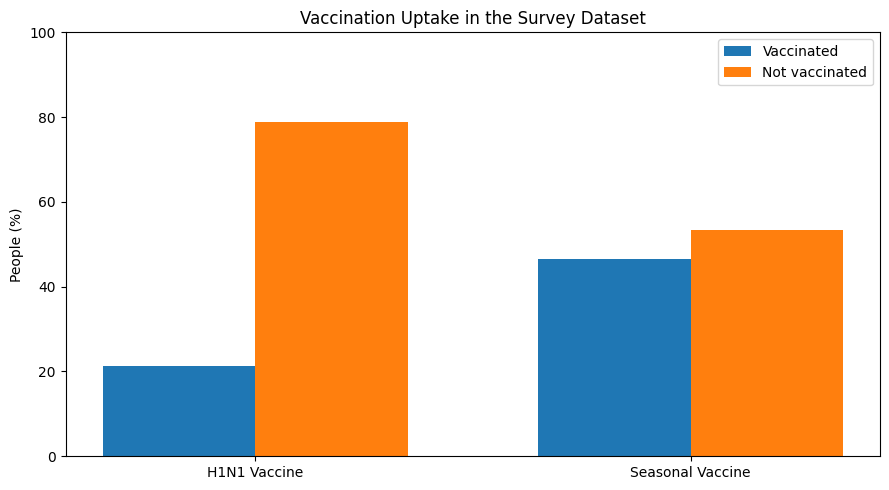

In [38]:

import matplotlib.pyplot as plt

# Calculate vaccination percentages
h1n1_rates = data["h1n1_vaccine"].value_counts(normalize=True).sort_index() * 100
seasonal_rates = data["seasonal_vaccine"].value_counts(normalize=True).sort_index() * 100

# Create the chart
categories = ["H1N1 Vaccine", "Seasonal Vaccine"]
vaccinated = [h1n1_rates[1], seasonal_rates[1]]
not_vaccinated = [h1n1_rates[0], seasonal_rates[0]]

x = range(len(categories))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(
    [i - width/2 for i in x],
    vaccinated,
    width,
    label="Vaccinated"
)
plt.bar(
    [i + width/2 for i in x],
    not_vaccinated,
    width,
    label="Not vaccinated"
)

plt.xticks(list(x), categories)
plt.ylabel("People (%)")
plt.title("Vaccination Uptake in the Survey Dataset")
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()
plt.show()


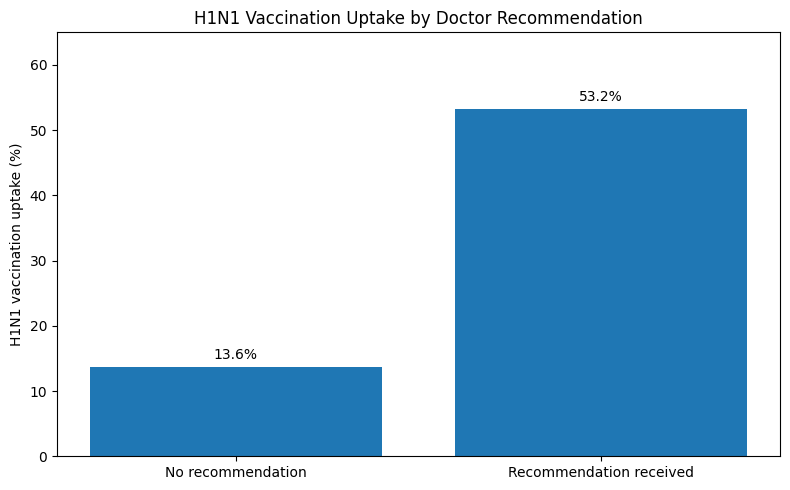

In [40]:

import matplotlib.pyplot as plt

# Remove rows with missing recommendation or vaccination data
recommendation_data = data.dropna(
    subset=["doctor_recc_h1n1", "h1n1_vaccine"]
).copy()

# Convert recommendation values to integers (0 or 1)
recommendation_data["doctor_recc_h1n1"] = (
    recommendation_data["doctor_recc_h1n1"].astype(int)
)

# Calculate vaccination uptake as a percentage
uptake = (
    recommendation_data.groupby("doctor_recc_h1n1")["h1n1_vaccine"]
    .mean() * 100
)

# Use numeric labels: 0 = No, 1 = Yes
labels = ["No recommendation", "Recommendation received"]
values = [uptake.loc[0], uptake.loc[1]]

# Draw the chart
plt.figure(figsize=(8, 5))
bars = plt.bar(labels, values)

plt.bar_label(bars, fmt="%.1f%%", padding=4)
plt.ylabel("H1N1 vaccination uptake (%)")
plt.title("H1N1 Vaccination Uptake by Doctor Recommendation")
plt.ylim(0, 65)
plt.tight_layout()
plt.show()


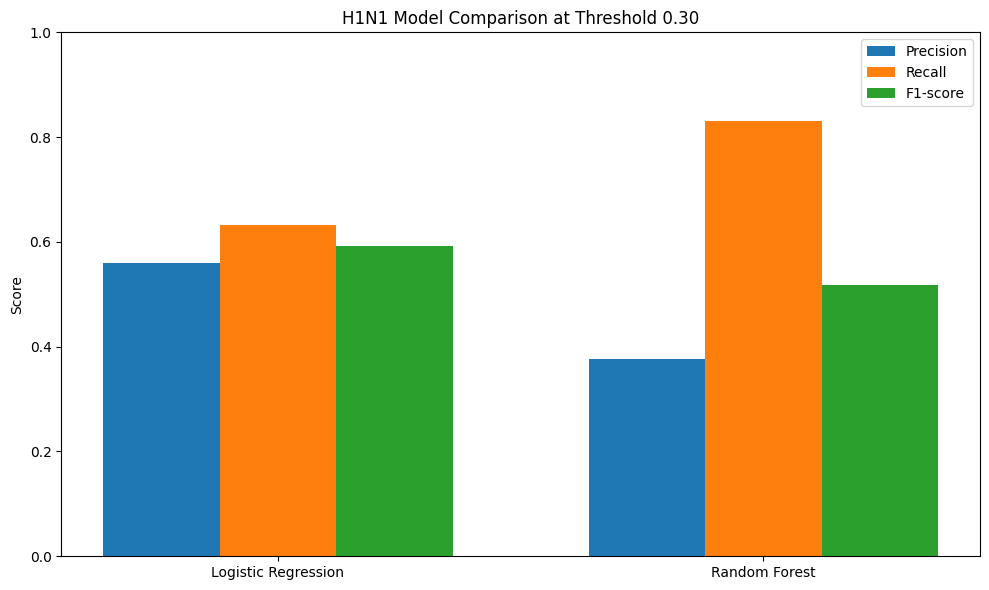

In [41]:

import matplotlib.pyplot as plt
import numpy as np

# Model performance from our validation experiments
models = ["Logistic Regression", "Random Forest"]

precision = [0.5588, 0.3759]
recall = [0.6317, 0.8317]
f1_score = [0.5931, 0.5178]

x = np.arange(len(models))
width = 0.24

plt.figure(figsize=(10, 6))

plt.bar(x - width, precision, width, label="Precision")
plt.bar(x, recall, width, label="Recall")
plt.bar(x + width, f1_score, width, label="F1-score")

plt.xticks(x, models)
plt.ylabel("Score")
plt.title("H1N1 Model Comparison at Threshold 0.30")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()


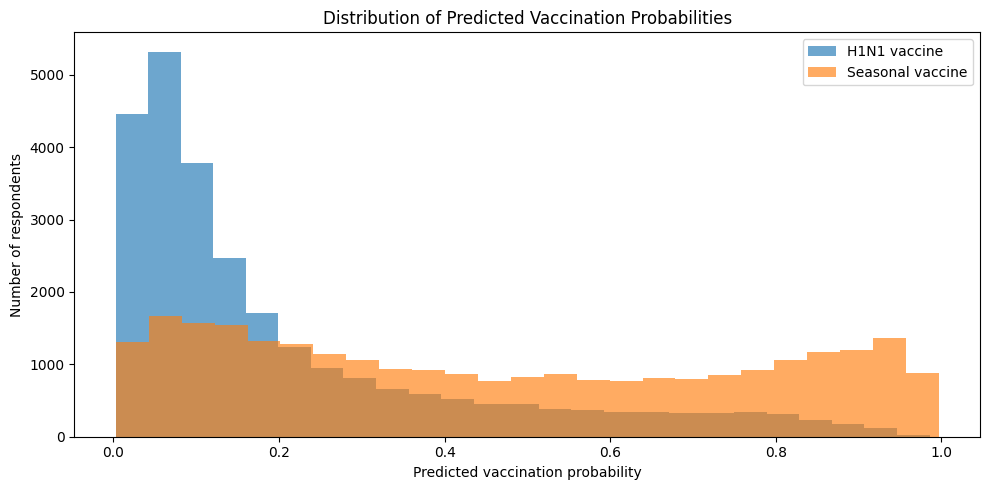

In [42]:

import matplotlib.pyplot as plt

# Plot the probabilities produced by our final models
plt.figure(figsize=(10, 5))

plt.hist(
    predictions_df["h1n1_vaccine_probability"],
    bins=25,
    alpha=0.65,
    label="H1N1 vaccine"
)

plt.hist(
    predictions_df["seasonal_vaccine_probability"],
    bins=25,
    alpha=0.65,
    label="Seasonal vaccine"
)

plt.xlabel("Predicted vaccination probability")
plt.ylabel("Number of respondents")
plt.title("Distribution of Predicted Vaccination Probabilities")
plt.legend()
plt.tight_layout()
plt.show()
